In [1]:
import json
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from results_loader import (MODELS, MODEL_LABELS, load_all, task_thresholds, asr_found, intent_hit, tex_name, setup_latex_plots, PCT, ordered, method_color)
from stats_utils import bootstrap_ci, wilson_ci
import paper_tables as pt

setup_latex_plots()
EXCLUDE_BASELINE_FAILURES = True  # True: drop sentences whose clean input already fails (ASR) / maps to the wrong intent
ROOT = "../outputs/results"
PRIMARY = MODELS[0]  # model of the single-model displays (spectrograms)

# baseline failures: clean input already fails (ASR: transcription != ground truth; intent: clean intent != reference)
asr_raw, intent_raw = load_all(ROOT, exclude_baseline_failures=False)
for model in MODELS:
    print(model, "baseline failures ASR:", {m: f"{np.mean([not r['original_passes'] for r in rs]):.1%}" for m, rs in asr_raw[model].items()})
    print(model, "baseline failures intent:", {m: f"{np.mean([not r['intent']['original_correct'] for r in rs]):.1%}" for m, rs in intent_raw[model].items()})

asr, intent = load_all(ROOT, exclude_baseline_failures=EXCLUDE_BASELINE_FAILURES)  # {model: {method: records}}
thr = task_thresholds(asr, intent)  # m-valid UTMOS thresholds per task
for model in MODELS:
    print(model, "n ASR:", {m: len(rs) for m, rs in asr[model].items()}, "| n intent:", {m: len(rs) for m, rs in intent[model].items()})

whisper-tiny baseline failures ASR: {'GATAS': '29.0%', 'Waveform': '29.0%', 'SMACK_untargeted': '28.0%', 'ALIF': '28.0%', 'PGD': '28.0%', 'SMACK': '28.0%'}
whisper-tiny baseline failures intent: {'GATAS': '2.0%', 'Waveform': '2.0%', 'SMACK': '2.0%', 'ALIF': '2.0%', 'PGD': '2.0%', 'GATAS_llm': '2.0%'}
wav2vec2-large baseline failures ASR: {'GATAS': '8.0%', 'Waveform': '8.0%', 'SMACK_untargeted': '8.0%', 'ALIF': '8.0%', 'SMACK': '8.0%'}
wav2vec2-large baseline failures intent: {'GATAS': '42.0%', 'Waveform': '42.0%', 'SMACK': '42.0%', 'ALIF': '42.0%', 'GATAS_llm': '42.0%'}
whisper-tiny n ASR: {'GATAS': 71, 'Waveform': 71, 'SMACK_untargeted': 72, 'ALIF': 72, 'PGD': 72, 'SMACK': 72} | n intent: {'GATAS': 98, 'Waveform': 98, 'SMACK': 98, 'ALIF': 98, 'PGD': 98, 'GATAS_llm': 98}
wav2vec2-large n ASR: {'GATAS': 92, 'Waveform': 92, 'SMACK_untargeted': 92, 'ALIF': 92, 'SMACK': 92} | n intent: {'GATAS': 58, 'Waveform': 58, 'SMACK': 58, 'ALIF': 58, 'GATAS_llm': 58}


### Effectiveness vs. naturalness
Mean with 95% CI (Wilson for rates, bootstrap for UTMOS). Top right is best: more test cases found, closer to natural speech (clean-audio UTMOS dashed).

Pooled over the attacked ASR models (sentences of all models together; PGD is white-box on Whisper and enters with Whisper only).

pooled n ASR: {'ALIF': 164, 'GATAS': 163, 'SMACK': 164, 'Waveform': 163, 'PGD': 72, 'SMACK_untargeted': 164} | intent: {'GATAS_llm': 156, 'ALIF': 156, 'GATAS': 156, 'SMACK': 156, 'Waveform': 156, 'PGD': 98}


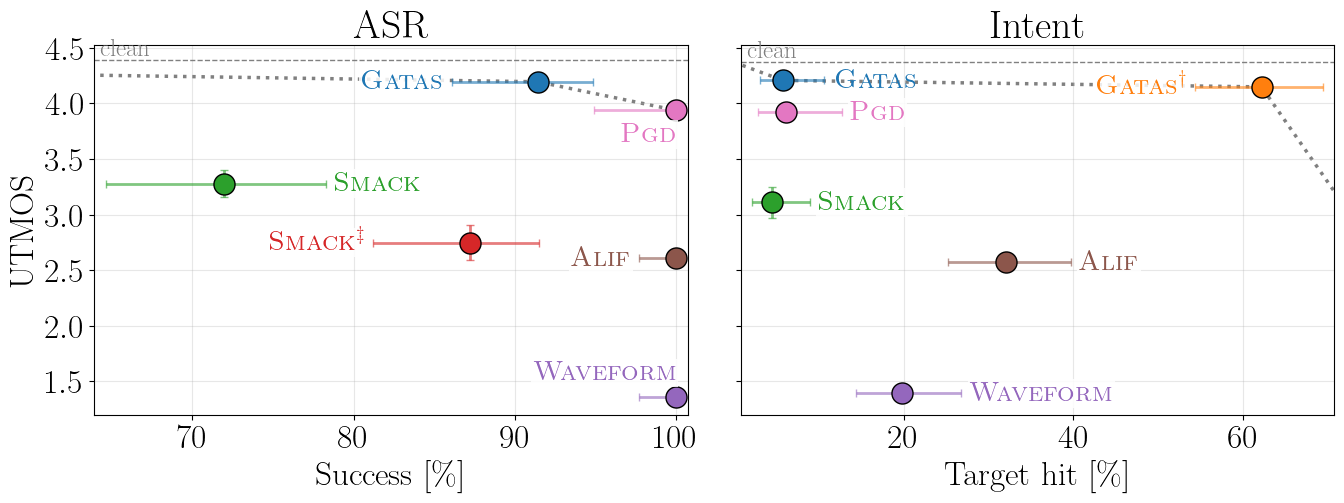

In [2]:
def tradeoff_panel(ax, records, success_fn, ylabel, title, x_key="utmos", clean_x=None, first=True):
    pts = []
    for m, recs in records.items():
        n = len(recs)
        k = sum(success_fn(r) for r in recs)
        y, (ylo, yhi) = k / n, wilson_ci(k, n)
        xs = [r[x_key] for r in recs]
        x, (xlo, xhi) = np.mean(xs), bootstrap_ci(xs)
        ax.errorbar(100 * y, x, xerr=[[100 * max(y - ylo, 0)], [100 * max(yhi - y, 0)]], yerr=[[max(x - xlo, 0)], [max(xhi - x, 0)]],
                    fmt="none", ecolor=method_color(m), alpha=0.6, lw=2, capsize=3, zorder=2)
        ax.scatter(100 * y, x, s=230, color=method_color(m), edgecolor="black", zorder=3)
        pts.append((m, 100 * y, x, method_color(m), 100 * yhi, 100 * ylo))
    ax.set_xlabel(ylabel + " [" + PCT + "]"); ax.set_ylabel("UTMOS" if first else ""); ax.set_title(title)
    ax.grid(alpha=0.3)

    # limits: data range plus a 2 % margin on both sides (rates never exceed 100 %); fixed so the front line cannot widen them
    lo_min, hi_max = min(p[5] for p in pts), max(p[4] for p in pts)
    margin = 0.02 * (hi_max - lo_min)
    ax.set_xlim(lo_min - margin, hi_max + margin)
    ax.set_xticks([t for t in ax.get_xticks() if 0 <= t <= 100 and lo_min - margin <= t <= hi_max + margin])
    ax.set_xlim(lo_min - margin, hi_max + margin)
    if clean_x is not None:
        ax.set_ylim(top=clean_x + 0.15)
    ax.autoscale(False)
    x0, x1 = ax.get_xlim()

    # clean-audio reference (dashed) and Pareto front (dotted) over the means: starts at (0, clean), ends horizontally at 100 %
    if clean_x is not None:
        ax.axhline(clean_x, color="gray", ls="--", lw=1)
        ax.text(x0 + 0.01 * (x1 - x0), clean_x, "clean", va="bottom", color="gray", fontsize=18)
    # anchors: no attack (0 % success, clean UTMOS) and a trivial 100 % success with UTMOS 0; they stay on the front unless dominated
    anchors = ([("clean", 0.0, clean_x)] if clean_x is not None else []) + [("max", 100.0, 0.0)]
    cand = [(p[0], p[1], p[2]) for p in pts] + anchors
    eps = 1e-9
    front = sorted([c for c in cand if not any(o is not c and o[1] >= c[1] - eps and o[2] >= c[2] - eps and (o[1] > c[1] + eps or o[2] > c[2] + eps) for o in cand)], key=lambda c: c[1])
    ax.plot([c[1] for c in front], [c[2] for c in front], color="gray", ls=":", lw=2.5, zorder=1)

    # labels beside the horizontal range (right, else left, else below/above), avoiding other ranges and labels
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    tr = ax.transData
    axbox = ax.get_window_extent()
    pad = 6
    obstacles = []
    for m, px, py, c, hi, lo in pts:
        (xa, ya), (xb, _) = tr.transform((lo, py)), tr.transform((hi, py))
        obstacles.append((xa - 14, ya - 14, xb + 14, ya + 14))
    def overlaps(r, o):
        return not (r[2] < o[0] or r[0] > o[2] or r[3] < o[1] or r[1] > o[3])
    for idx, (m, px, py, c, hi, lo) in enumerate(pts):
        others = obstacles[:idx] + obstacles[idx + 1:]
        (xl, yp), (xh, _) = tr.transform((lo, py)), tr.transform((hi, py))
        options = [("left", xh + 8, yp, "left", "center"), ("right", xl - 8, yp, "right", "center"),
                   ("below", xh, yp - 24, "right", "center"), ("above", xh, yp + 24, "right", "center"),
                   ("below2", xh, yp - 40, "right", "center"), ("above2", xh, yp + 40, "right", "center")]
        for name, xx, yy, ha, va in options:
            t = ax.annotate(tex_name(m), tr.inverted().transform((xx, yy)), ha=ha, va=va, fontsize=20, color=c, zorder=4,
                            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
            bb = t.get_window_extent(renderer)
            r = (bb.x0 - pad, bb.y0 - pad, bb.x1 + pad, bb.y1 + pad)
            inside = r[0] >= axbox.x0 and r[2] <= axbox.x1 and r[1] >= axbox.y0 and r[3] <= axbox.y1
            if inside and not any(overlaps(r, o) for o in others):
                obstacles.append(r)
                break
            t.remove()
        else:  # nothing free: fall back to the right
            ax.annotate(tex_name(m), (hi, py), textcoords="offset points", xytext=(8, 0), ha="left", va="center", fontsize=20, color=c)

def pooled(data):
    """Records of a method pooled over the attacked models that have it: {method: records}."""
    methods = {m for model in MODELS for m in data.get(model, {})}
    return {m: [r for model in MODELS for r in data.get(model, {}).get(m, [])] for m in methods}

# aggregated over the attacked ASR models (PGD is white-box on Whisper and enters with Whisper only)
asr_pool, intent_pool = pooled(asr), pooled(intent)
print("pooled n ASR:", {m: len(rs) for m, rs in asr_pool.items()}, "| intent:", {m: len(rs) for m, rs in intent_pool.items()})

with plt.rc_context({"font.size": 24}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True, gridspec_kw={"wspace": 0.09})
    tradeoff_panel(axes[0], asr_pool, asr_found, "Success", "ASR",
                   clean_x=np.mean([r["utmos_original"] for r in asr_pool["GATAS"]]))
    tradeoff_panel(axes[1], intent_pool, intent_hit, "Target hit", "Intent",
                   clean_x=np.mean([r["utmos_original"] for r in intent_pool["GATAS"]]), first=False)
    plt.savefig("_figures/tradeoff_methods.pdf", bbox_inches="tight")

In [3]:
CLASSES = [("preserved", "Preserved", "lightgray"), ("changed", "Changed", "tab:blue"), ("garbled", "Garbled", "tab:orange")]
with plt.rc_context({"font.size": 16}):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 4), sharey=False, squeeze=False)
    for ax, model in zip(axes[0], MODELS):
        methods = ordered(m for m in asr[model] if m in pt.ASR_ORDER)
        for y, m in enumerate(methods):
            vs = [pt.verdict(r) for r in asr[model][m]]
            left = 0
            for key, label, color in CLASSES:
                share = 100 * np.mean([v == key for v in vs])
                ax.barh(y, share, left=left, color=color, edgecolor="white", label=label if y == 0 else None)
                if share >= 4:
                    ax.text(left + share / 2, y, f"{share:.0f}", ha="center", va="center", fontsize=13)
                left += share
        ax.set_yticks(range(len(methods))); ax.set_yticklabels([tex_name(m) for m in methods]); ax.invert_yaxis()
        ax.set_xlim(0, 100); ax.set_xlabel(r"Sentences [\%]"); ax.set_title(MODEL_LABELS[model])
    axes[0, 0].legend(loc="upper center", bbox_to_anchor=(1.0, -0.22), ncol=3, frameon=False)
    plt.savefig("_figures/semantic_classes.pdf", bbox_inches="tight")


## Spectrogram comparison
Per method: original, final candidate, difference (candidate - original) for the same sentence.

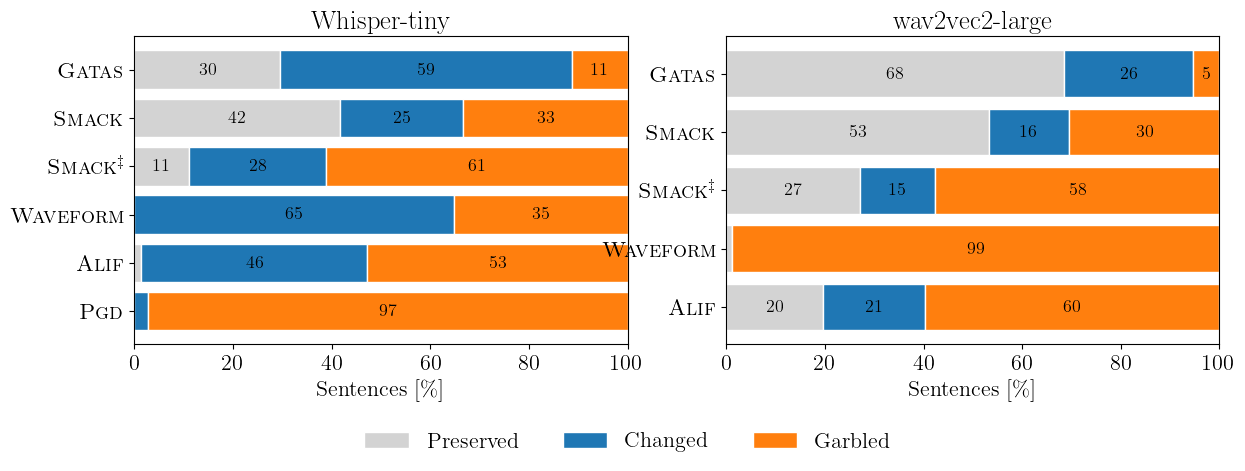

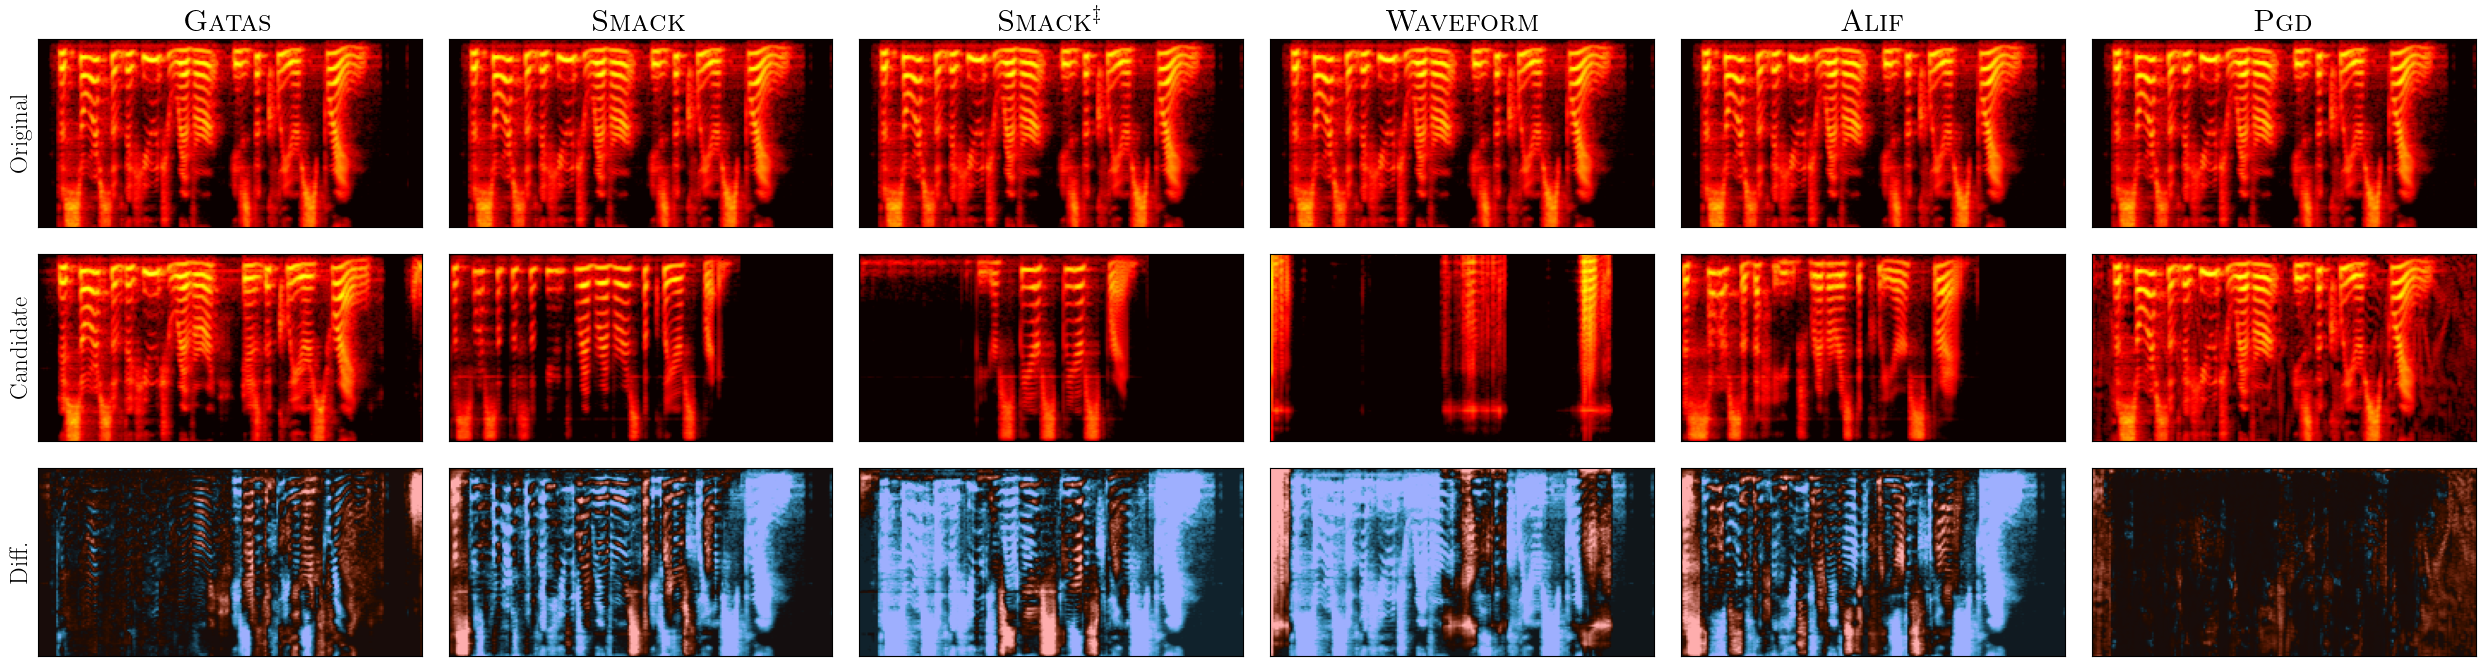

In [4]:
def to_spectrogram(file):
    y, sr = librosa.load(file, sr=None)
    return librosa.power_to_db(np.abs(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=256, n_mels=128)))

def fit(spec, T):
    if spec.shape[1] < T:
        spec = np.pad(spec, ((0, 0), (0, T - spec.shape[1])), constant_values=spec.min())
    return spec[:, :T]

def spectrogram_grid(records, sentence_id, tag):
    ms = ordered(m for m, rs in records.items() if any(r["sentence_id"] == sentence_id for r in rs))
    fig, axes = plt.subplots(3, len(ms), figsize=(4.2 * len(ms), 7), squeeze=False)
    for j, m in enumerate(ms):
        r = next(r for r in records[m] if r["sentence_id"] == sentence_id)
        g, b = to_spectrogram(r["gt_wav"]), to_spectrogram(r["adv_wav"])
        T = max(g.shape[1], b.shape[1]); g, b = fit(g, T), fit(b, T)
        for i, (img, title) in enumerate(zip([g, b, b - g], ["Original", "Candidate", "Diff."])):
            ax = axes[i, j]
            if i < 2:
                ax.imshow(img, cmap="hot", vmin=-60, vmax=40, aspect="auto")
            else:
                ax.imshow(img, cmap="berlin", norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40), aspect="auto")
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(title)
            if i == 0: ax.set_title(tex_name(m))
    plt.tight_layout()
    plt.savefig(f"_figures/spec_{tag}_{sentence_id:03d}.jpg", dpi=200, bbox_inches="tight")
    plt.show()

spectrogram_grid(asr[PRIMARY], 13, "asr")

## RQ1 paper table (`_tables/rq1.tex`)

One table, panels for ASR testing and intent matching, column groups per attacked model: test cases found (ASR: transcription differs; intent: intent changed and target hit), WER, semantic and spectrogram distance, UTMOS and the share of m-valid test cases (UTMOS threshold per task, `task_thresholds`). The reference method is GATAS on ASR and GATAS$^\dagger$ (GATAS_llm) on intent matching. A baseline cell gets a **colored bullet** when the reference is significantly better in this model, task and measure: one-sided paired tests (exact McNemar for the rates, Wilcoxon signed-rank for the continuous measures), Holm-corrected over the baselines, p < 0.05; the bullet color gives the size of the paired Cohen's d_z (also for the 0/1 measures; positive: reference better): small ≤ 0.5, medium ≤ 1, large > 1. The two-sided analyses above stay as the exhaustive statistics.

In [5]:
import os
os.makedirs("_tables", exist_ok=True)
for old in ("rq1_stats", "rq1_full", "rq1_intent_full", "rq1_intent"):  # replaced by the single table
    if os.path.exists(f"_tables/{old}.tex"):
        os.remove(f"_tables/{old}.tex")
tex = pt.rq1_tex(asr, intent, thr)
open("_tables/rq1.tex", "w").write(tex + "\n")
print("% tables/rq1.tex"); print(tex)

% tables/rq1.tex
\begin{table*}[t]
\caption{Effectiveness (RQ\textsubscript{1}) on (a) ASR testing and (b) intent matching: test cases found, lexical (WER), semantic and spectrogram distance to the clean audio, naturalness (UTMOS) and the share of m-valid test cases. Bold: best value. The reference method is \tool on ASR and \gllm on intent matching; A colored bullet marks a significant difference to the reference method (one-sided paired test, Holm-corrected, $p<0.05$) and the size of the paired Cohen's $d_z$: \textcolor{orange!80!black}{$\bullet$}~small ($d_z\le0.5$), \textcolor{blue!70}{$\bullet$}~medium ($0.5<d_z\le1$), \textcolor{green!50!black}{$\bullet$}~large ($d_z>1$). \pgd is white-box on Whisper and has no wav2vec2 run.}
\label{tab:rq1}
\centering
\small
\textbf{(a) ASR testing}\\[2pt]
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccccccccc}\toprule
 & \multicolumn{6}{c}{Whisper-tiny} & \multicolumn{6}{c}{wav2vec2-large} \\
\cmidrule(lr){2-7}\cmidrule(lr){8-13}
 & Found [\